In [1]:
import anndata
import scvelo as scv
import pandas as pd
import numpy as np
import matplotlib as plt
import matplotlib.pyplot as plt  # 从 matplotlib.pyplot 导入 plt

In [2]:
scv.set_figure_params()

In [55]:
sample_1 = anndata.read_loom("../Ha_testis/removeAlleleBias/cellRanger/02.cellranger/Ha_testis_v9anno/velocyto/Ha_testis_v9anno.loom")
sample_1.var_names_make_unique()

#显示出数据的前10行
#sample_1_df = sample_1.to_df().head(10)
#print(sample_1_df)

sample_1.obs = sample_1.obs.rename(index=lambda x: x.replace('Ha_testis_v9anno:', 'Hab_'))
sample_1.obs = sample_1.obs.rename(index=lambda x: x.replace('x', ''))
sample_1


AnnData object with n_obs × n_vars = 10145 × 23452
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand'
    layers: 'matrix', 'ambiguous', 'spliced', 'unspliced'

In [56]:

print(sample_1.var.columns)
sample_1.var.head

Index(['Accession', 'Chromosome', 'End', 'Start', 'Strand'], dtype='object')


<bound method NDFrame.head of              Accession Chromosome     End   Start Strand
Gene                                                    
HaiMa00001  HaiMa00001          1   12971   10717      -
HaiMa00002  HaiMa00002          1   63432   12996      -
HaiMa00005  HaiMa00005          1  205267   83152      -
HaiMa00006  HaiMa00006          1  251675  205721      -
HaiMa00007  HaiMa00007          1  292886  281048      -
...                ...        ...     ...     ...    ...
MT-ND3          MT-ND3   KT362140    9985    9637      +
MT-ND4L        MT-ND4L   KT362140   10351   10055      +
MT-ND4          MT-ND4   KT362140   11725   10345      +
MT-ND5          MT-ND5   KT362140   13772   11937      +
MT-CYTB        MT-CYTB   KT362140   15503   14363      +

[23452 rows x 5 columns]>

In [57]:
# update feature from Ha_ID to zbfID -------------
# 读入 HaID 和zbf ID 的转换文件
raw_anno = pd.read_csv("/data/home/zhou3lab/suqianwei/project/seahorse/13.singcell/Ha_testis/removeAlleleBias/cellRanger/02.cellranger/Ha_testis_v9anno/outs/filtered_feature_bc_matrix/convertDreID/Ha_Cint_Mbr_zbfens99_singleCopy.convert3", sep = "\t", header = 0)
Ha_anno = raw_anno[["Ha", "LLgeneSymbol"]].rename(columns={"Ha": "geneID", "LLgeneSymbol": "new_features"})
Ha_anno = Ha_anno.drop_duplicates(subset="geneID", keep="first")
Ha_anno = Ha_anno.set_index('geneID')
sample_1.var['Ha_rawID'] = sample_1.var.index
sample_1.var["Gene"] = sample_1.var.Ha_rawID.map(Ha_anno["new_features"])
sample_1.var['Gene'] = sample_1.var['Gene'].fillna(sample_1.var['Ha_rawID'])
sample_1.var.index = sample_1.var["Gene"]
sample_1.var

,Accession,Chromosome,End,Start,Strand,Ha_rawID,Gene
Gene,,,,,,,
HaiMa00001,HaiMa00001,1,12971,10717,-,HaiMa00001,HaiMa00001
HaiMa00002,HaiMa00002,1,63432,12996,-,HaiMa00002,HaiMa00002
lama5,HaiMa00005,1,205267,83152,-,HaiMa00005,lama5
HaiMa00006,HaiMa00006,1,251675,205721,-,HaiMa00006,HaiMa00006
HaiMa00007,HaiMa00007,1,292886,281048,-,HaiMa00007,HaiMa00007
...,...,...,...,...,...,...,...
MT-ND3,MT-ND3,KT362140,9985,9637,+,MT-ND3,MT-ND3
MT-ND4L,MT-ND4L,KT362140,10351,10055,+,MT-ND4L,MT-ND4L
MT-ND4,MT-ND4,KT362140,11725,10345,+,MT-ND4,MT-ND4


In [24]:
raw_anno

,Cin,Mbr,Ha,zbf,LLgeneSymbol
1,fahd1_Cint,g8983,HaiMa09898,ENSDARG00000031657,fahd1
2,zgc_161969_Cint,g9010,HaiMa09868,ENSDARG00000041359,zgc:161969
3,aimp2_Cint,g9009,HaiMa09869,ENSDARG00000018903,aimp2
4,recql5_Cint,g8769,HaiMa09194,ENSDARG00000059556,recql5
5,tyk2_Cint,g9142,HaiMa09510,ENSDARG00000020326,tyk2
...,...,...,...,...,...
10072,LOC130932194_Cint,g8818,HaiMa09056,ENSDARG00000088145,atg4db
10073,LOC130932177_Cint,g12151,HaiMa01373,ENSDARG00000088950,sycp2
10074,e4f1_Cint,g8979,HaiMa09902,ENSDARG00000038243,e4f1
10075,LOC130932197_Cint,g8982,HaiMa09899,ENSDARG00000025338,hagh


In [27]:
# Cint loom data
sample_2 = anndata.read_loom("../Cint_testis/CintTestis_v3/velocyto/CintTestis_v3.loom")
sample_2.var_names_make_unique()
sample_2.obs = sample_2.obs.rename(index=lambda x: x.replace('CintTestis_v3:', 'Cin_'))
sample_2.obs = sample_2.obs.rename(index=lambda x: x.replace('x', ''))
sample_2.obs

""
CellID
Cin_AACCACAGTCCTGTCT
Cin_AACCATGGTTTCGGCG
Cin_AAACCCAAGACATAAC
Cin_AACGTCACAAGCGCAA
Cin_AAGATAGTCTTACTGT
...
Cin_TTTCCTCAGTTAGAAC
Cin_TTTGGTTGTCCAAGAG
Cin_TTTGGAGCAAGATTGA


In [33]:
# Cint ID convert
Cin_anno = raw_anno[["Cin", "LLgeneSymbol"]].rename(columns={"Cin": "geneID", "LLgeneSymbol": "new_features"})
Cin_anno = Cin_anno.drop_duplicates(subset="geneID", keep="first")
Cin_anno = Cin_anno.set_index('geneID')
Cin_anno
sample_2.var['Cin_rawID'] = sample_2.var.index
sample_2.var["Gene"] = sample_2.var.Cin_rawID.map(Cin_anno["new_features"])
sample_2.var['Gene'] = sample_2.var['Gene'].fillna(sample_2.var['Cin_rawID'])
sample_2.var.index = sample_2.var["Gene"]
sample_2.var

,Accession,Chromosome,End,Start,Strand,Cin_rawID,Gene
Gene,,,,,,,
MT-ND6,MT-ND6,KJ139455.1,14475,13954,-,MT-ND6,MT-ND6
MT-ND1,MT-ND1,KJ139455.1,4023,3050,+,MT-ND1,MT-ND1
MT-ND2,MT-ND2,KJ139455.1,5275,4234,+,MT-ND2,MT-ND2
MT-COX1,MT-COX1,KJ139455.1,7210,5660,+,MT-COX1,MT-COX1
MT-COX2,MT-COX2,KJ139455.1,8048,7358,+,MT-COX2,MT-COX2
...,...,...,...,...,...,...,...
LOC130911769,LOC130911769,NW_026651666.1,25007,24841,+,LOC130911769,LOC130911769
LOC130911770,LOC130911770,NW_026651666.1,25878,25767,+,LOC130911770,LOC130911770
LOC130911778,LOC130911778,NW_026651667.1,1760,702,-,LOC130911778,LOC130911778


In [34]:
# zbf loom data read
sample_3 = anndata.read_loom("../published/zebrafish/Frontiers_2022/02.run/zbfTestis/velocyto/zbfTestis.loom")
sample_3.var_names_make_unique()
sample_3.obs = sample_3.obs.rename(index=lambda x: x.replace('zbfTestis:', ''))
sample_3.obs = sample_3.obs.rename(index=lambda x: x.replace('x', ''))
sample_3.obs

""
CellID
AAACGAAAGAGTCTTC
AAACCCACAACGCCCA
AAACGCTTCTAGGCCG
AAACGAAAGTGATTCC
AAAGGGCGTTAGGGTG
...
TTTGGAGAGGGCGAGA
TTTGGAGAGCTTCGTA
TTTGATCTCGTGGCGT


In [65]:
# Mbr loom data read
sample_4 = anndata.read_loom("../Mbr_testis/removeAlleleBias/cellRanger/02.dnbc4tools/Mbr_testis3/output/out_246ZC.loom")
sample_4.var_names_make_unique()
sample_4.obs = sample_4.obs.rename(index=lambda x: x.replace('out_246ZC:', 'Mbr_'))
sample_4.obs = sample_4.obs.rename(index=lambda x: x.replace('x', ''))
sample_4.obs

""
CellID
Mbr_CELL10093_N2
Mbr_CELL10113_N5
Mbr_CELL10024_N3
Mbr_CELL1013_N4
Mbr_CELL10055_N2
...
Mbr_CELL9863_N2
Mbr_CELL987_N4
Mbr_CELL985_N6


In [66]:
# Mbr geneID convert
Mbr_anno = raw_anno[["Mbr", "LLgeneSymbol"]].rename(columns={"Mbr": "geneID", "LLgeneSymbol": "new_features"})
Mbr_anno = Mbr_anno.drop_duplicates(subset="geneID", keep="first")
Mbr_anno = Mbr_anno.set_index('geneID')
Mbr_anno
sample_4.var['Mbr_rawID'] = sample_4.var.index
sample_4.var["Gene"] = sample_4.var.Mbr_rawID.map(Mbr_anno["new_features"])
sample_4.var['Gene'] = sample_4.var['Gene'].fillna(sample_4.var['Mbr_rawID'])
sample_4.var.index = sample_4.var["Gene"]
sample_4.var

,Accession,Chromosome,End,Start,Strand,Mbr_rawID,Gene
Gene,,,,,,,
g2,g2,1,71499,63001,-,g2,g2
g3,g3,1,88016,77547,-,g3,g3
g4,g4,1,142117,124646,-,g4,g4
tp53i11b,g5,1,164868,151969,-,g5,tp53i11b
g6,g6,1,224274,212336,-,g6,g6
...,...,...,...,...,...,...,...
MT-ND3,MT-ND3,MT230531.1,9946,9598,+,MT-ND3,MT-ND3
MT-ND4L,MT-ND4L,MT230531.1,10313,10017,+,MT-ND4L,MT-ND4L
MT-ND4,MT-ND4,MT230531.1,11687,10307,+,MT-ND4,MT-ND4


In [67]:
# 取每个 sample 的 geneID 集合
s1 = set(sample_1.var.index)
s2 = set(sample_2.var.index)
s3 = set(sample_3.var.index)
s4 = set(sample_4.var.index)

# 求四个集合的交集
common_genes = s1 & s2 & s3 & s4

# 打印数量
print(f"四个 sample 共有的 geneID 数量: {len(common_genes)}")

四个 sample 共有的 geneID 数量: 8158


In [68]:
#合并并处理数据
sample_all = sample_1.concatenate(sample_2,sample_3,sample_4)
sample_all

AnnData object with n_obs × n_vars = 43394 × 8158
    obs: 'batch'
    var: 'Accession-0', 'Chromosome-0', 'End-0', 'Start-0', 'Strand-0', 'Ha_rawID-0', 'Gene-0', 'Accession-1', 'Chromosome-1', 'End-1', 'Start-1', 'Strand-1', 'Gene-1', 'Cin_rawID-1', 'Accession-2', 'Chromosome-2', 'End-2', 'Start-2', 'Strand-2', 'Accession-3', 'Chromosome-3', 'End-3', 'Start-3', 'Strand-3', 'Gene-3', 'Mbr_rawID-3'
    layers: 'matrix', 'ambiguous', 'spliced', 'unspliced'

In [69]:
sample_all.obs

,batch
CellID,
Hab_AAATGGATCACACGAT-0,0
Hab_AACAACCAGCCTATTG-0,0
Hab_AACAAAGGTAACGCGA-0,0
Hab_AAAGTGAAGCCTCCAG-0,0
Hab_AAAGTCCAGACTCTAC-0,0
...,...
Mbr_CELL9863_N2-3,3
Mbr_CELL987_N4-3,3
Mbr_CELL985_N6-3,3


In [70]:
#处理合并后的cellID
#sample_all.obs = sample_all.obs.rename(index=lambda x: x.replace(':', ''))
sample_all.obs = sample_all.obs.rename(index=lambda x: x.replace('-0', '-1'))
sample_all.obs = sample_all.obs.rename(index=lambda x: x.replace('-1', '-1'))
sample_all.obs = sample_all.obs.rename(index=lambda x: x.replace('-2', '-1'))
sample_all.obs = sample_all.obs.rename(index=lambda x: x.replace('-3', ''))
#sample_all.obs = sample_all.obs.rename(index=lambda x: x.replace('-1-3', '-1'))
sample_all.obs

,batch
CellID,
Hab_AAATGGATCACACGAT-1,0
Hab_AACAACCAGCCTATTG-1,0
Hab_AACAAAGGTAACGCGA-1,0
Hab_AAAGTGAAGCCTCCAG-1,0
Hab_AAAGTCCAGACTCTAC-1,0
...,...
Mbr_CELL9863_N2,3
Mbr_CELL987_N4,3
Mbr_CELL985_N6,3


In [72]:
# 查看整合后cellID有无重复项
sample_all.obs.index.duplicated().any()
sample_obs = pd.DataFrame(sample_all.obs.index)
sample_obs

,CellID
0,Hab_AAATGGATCACACGAT-1
1,Hab_AACAACCAGCCTATTG-1
2,Hab_AACAAAGGTAACGCGA-1
3,Hab_AAAGTGAAGCCTCCAG-1
4,Hab_AAAGTCCAGACTCTAC-1
...,...
43389,Mbr_CELL9863_N2
43390,Mbr_CELL987_N4
43391,Mbr_CELL985_N6
43392,Mbr_CELL9855_N2


In [73]:
#umap 读取
umap = pd.read_csv('anno_info/combined_HaCintMbr_Zbfmo5pei_umap_embeddings_final.2.csv')
umap
umap = umap.rename(columns={"Unnamed: 0": 'CellID'})
umap
used_cellID = umap.CellID
used_cellID

0        AAACCCAAGAAACCCG-1
1        AAACCCAAGCCAGTAG-1
2        AAACCCAAGCTCGTGC-1
3        AAACCCAAGCTGGTGA-1
4        AAACCCAAGCTTAGTC-1
                ...        
33521      Mbr_CELL56114_N1
33522      Mbr_CELL56115_N1
33523      Mbr_CELL56116_N1
33524      Mbr_CELL56117_N1
33525      Mbr_CELL56126_N1
Name: CellID, Length: 33526, dtype: object

In [74]:
#cell_clusters读取
cell_clusters = pd.read_table('anno_info/combined_HaCintMbr_Zbfmo5pei_annotation_final.2.table')
cell_clusters = cell_clusters[["seurat_clusters","combinedCluster"]]
cell_clusters["CellID"] = cell_clusters.index
cell_clusters

,seurat_clusters,combinedCluster,CellID
AAACCCAAGAAACCCG-1,12,spermatocyte,AAACCCAAGAAACCCG-1
AAACCCAAGCCAGTAG-1,0,early spermatids,AAACCCAAGCCAGTAG-1
AAACCCAAGCTCGTGC-1,3,late spermatids,AAACCCAAGCTCGTGC-1
AAACCCAAGCTGGTGA-1,3,late spermatids,AAACCCAAGCTGGTGA-1
AAACCCAAGCTTAGTC-1,11,spermatogonia,AAACCCAAGCTTAGTC-1
...,...,...,...
Mbr_CELL56114_N1,11,spermatogonia,Mbr_CELL56114_N1
Mbr_CELL56115_N1,3,late spermatids,Mbr_CELL56115_N1
Mbr_CELL56116_N1,3,late spermatids,Mbr_CELL56116_N1
Mbr_CELL56117_N1,11,spermatogonia,Mbr_CELL56117_N1


In [75]:
sample_all_index = pd.DataFrame(sample_all.obs.index)
sample_all_index

,CellID
0,Hab_AAATGGATCACACGAT-1
1,Hab_AACAACCAGCCTATTG-1
2,Hab_AACAAAGGTAACGCGA-1
3,Hab_AAAGTGAAGCCTCCAG-1
4,Hab_AAAGTCCAGACTCTAC-1
...,...
43389,Mbr_CELL9863_N2
43390,Mbr_CELL987_N4
43391,Mbr_CELL985_N6
43392,Mbr_CELL9855_N2


In [76]:
#查找链接的锚点
sample_all = sample_all[np.isin(sample_all.obs.index, used_cellID)]
sample_all.obs

,batch
CellID,
Hab_AACAAAGGTAACGCGA-1,0
Hab_AAACGAACACATAGCT-1,0
Hab_AAAGGATCACAAGCTT-1,0
Hab_AAACCCAAGATTGGGC-1,0
Hab_AAACGAACAAATGCGG-1,0
...,...
Mbr_CELL9863_N2,3
Mbr_CELL987_N4,3
Mbr_CELL985_N6,3


In [77]:
#调整顺序
# 对UMAP坐标文件取交集
umap_ordered = sample_all_index.merge(umap, on="CellID")
umap_ordered.head()
# 对细胞类群文件细胞取交集
# order
cell_clusters = sample_all_index.merge(cell_clusters, on="CellID")
cell_clusters.head()

# 将umap信息加入sample_all
umap_ordered = umap_ordered.iloc[:, 1:]
sample_all.obsm['X_umap'] = umap_ordered.values


In [81]:
# 将cell_clusters加入sample_all
cell_clusters_ordered = cell_clusters.iloc[:, 2]
cell_clusters_ordered
sample_all.obs['cell_clusters'] = cell_clusters_ordered.values



In [82]:
# Running RNA Velocity
scv.pp.filter_and_normalize(sample_all, min_shared_counts=30, n_top_genes=2000)
scv.pp.moments(sample_all, n_pcs=30, n_neighbors=30)
scv.tl.velocity(sample_all, mode="stochastic")
scv.tl.velocity_graph(sample_all)

Filtered out 864 genes that are detected 30 counts (shared).
Normalized count data: X, spliced, unspliced.
Extracted 2000 highly variable genes.
Logarithmized X.


/share/home/zhou3lab/suqianwei/miniconda3/envs/mamba/envs/cellrank2/lib/python3.10/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)
/tmp/ipykernel_11799/1045558248.py:3: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scv.pp.moments(sample_all, n_pcs=30, n_neighbors=30)
/share/home/zhou3lab/suqianwei/miniconda3/envs/mamba/envs/cellrank2/lib/python3.10/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(
/share/home/zhou3lab/suqianwei/miniconda3/envs/mamba/envs/cellrank2/lib/python3.10/site-packages/scvelo/preprocessing/neighbors.py:

computing neighbors
    finished (0:00:25) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:02) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities


/share/home/zhou3lab/suqianwei/miniconda3/envs/mamba/envs/cellrank2/lib/python3.10/site-packages/scvelo/tools/optimization.py:184: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  gamma[i] = np.linalg.pinv(A.T.dot(A)).dot(A.T.dot(y[:, i]))


    finished (0:00:09) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/88 cores)


  0%|          | 0/31839 [00:00<?, ?cells/s]

    finished (0:01:39) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


computing velocity embedding
    finished (0:00:06) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


/share/home/zhou3lab/suqianwei/miniconda3/envs/mamba/envs/cellrank2/lib/python3.10/site-packages/matplotlib/backends/backend_pdf.py:1761: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(rgb8, mode='P')


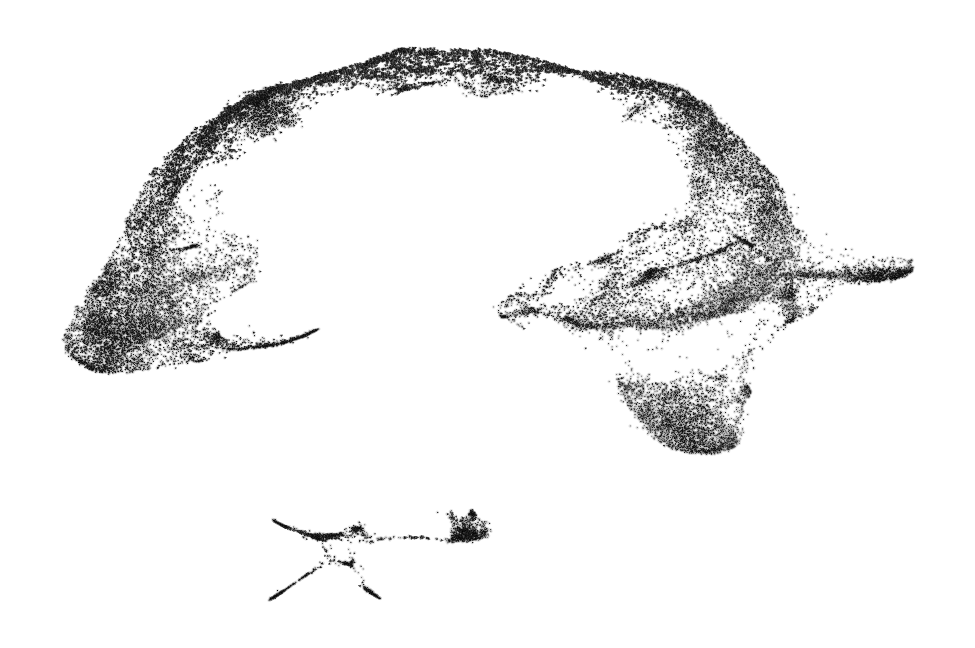

In [83]:
#向量场图

scv.pl.velocity_embedding(sample_all, basis='X_umap', arrow_size=5, show=False)
plt.savefig("figures/combined_velocity.pdf", bbox_inches="tight", dpi=300)

# 手动显示（可选，检查是否绘图成功）
plt.show()

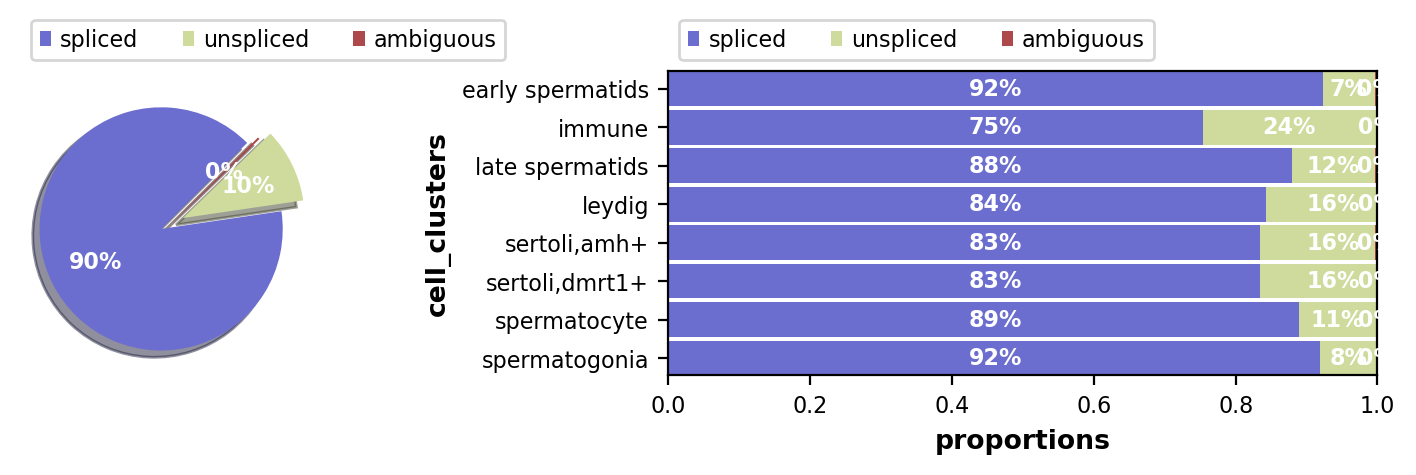

<Figure size 600x400 with 0 Axes>

In [84]:
#饼图，柱状图
scv.pl.proportions(sample_all,groupby="cell_clusters")
plt.savefig("figures/combined_proportions_tsne.pdf", bbox_inches="tight", dpi=300)

/share/home/zhou3lab/suqianwei/miniconda3/envs/mamba/envs/cellrank2/lib/python3.10/site-packages/scvelo/plotting/utils.py:68: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  return isinstance(c, str) and c in data.obs.keys() and cat(data.obs[c])
/share/home/zhou3lab/suqianwei/miniconda3/envs/mamba/envs/cellrank2/lib/python3.10/site-packages/scvelo/plotting/utils.py:68: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  return isinstance(c, str) and c in data.obs.keys() and cat(data.obs[c])
/share/home/zhou3lab/suqianwei/miniconda3/envs/mamba/envs/cellrank2/lib/python3.10/site-packages/scvelo/plotting/utils.py:65: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  return cat(data)  # if data is 

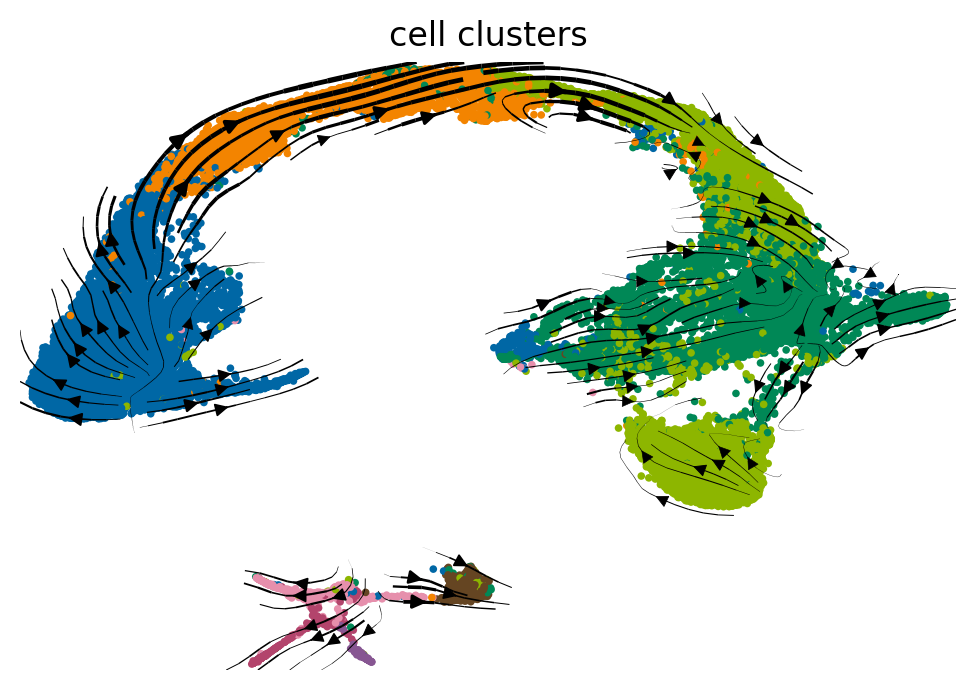

In [86]:
#流图
my_cols = {
    'spermatogonia': '#0067a5',
    'spermatocyte': '#f38400',
    'early spermatids': "#8db600",
    'late spermatids': '#008856',
    'sertoli,dmrt1+': '#e68fac',
    'sertoli,amh+': '#b3446c',
    'leydig': "#875692",
    'immune': '#654522',
    'unknown': '#bebebe'
}
scv.pl.velocity_embedding_stream(
    sample_all,
    basis='X_umap',
    color="cell_clusters",
    palette=my_cols,        # 设置颜色
    size=30,
    legend_loc=False,
    alpha=1,
    title=None,
    show=False
)
plt.savefig("figures/combined_velocity.svg", bbox_inches="tight", dpi=300)